
# Image Colorization using CNN Autoencoder

## Deep Learning Assignment Report

This notebook implements an image colorization system using a pre-trained convolutional autoencoder network.

The model receives grayscale images and predicts the missing color information in the Lab color space.

The notebook includes:

1. Loading the pretrained CNN autoencoder model
2. Two preprocessing methods for grayscale conversion
3. Color reconstruction using Lab color space
4. Comparison between preprocessing methods
5. Stability experiments:
   - Rotation
   - Gaussian Noise
   - Brightness changes
6. Analysis and final conclusions



# Section 1 — Imports and Setup

In this section:

- Required libraries are imported
- Image size and model path are configured
- Input image paths are defined

The implementation uses:

- TensorFlow/Keras for loading the neural network
- OpenCV for image processing
- scikit-image for Lab color space conversion
- Matplotlib for visualization


In [16]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from skimage.color import rgb2lab, lab2rgb
from scipy.ndimage import rotate

IMG_SIZE = 256

MODEL_PATH = 'colorize_autoencoder_first1000.keras'

IMAGE_PATHS = [
    'forest.397.jpg',
    'forest.399.jpg',
    'YIN8QU2CC97X.jpg',
    'ZYLOMHW6DWLE.jpg'
]

print("Setup completed.")


Setup completed.



# Section 2 — Loading the Pretrained CNN Autoencoder

The pretrained colorization model is loaded using TensorFlow/Keras.

The network architecture is based on a convolutional Encoder-Decoder Autoencoder.

## Model Characteristics

### Input
- Single-channel L component from Lab color space
- Shape: `256×256×1`
- L values range from `0` to `100`

### Output
- Two-channel `(a,b)` color components
- Final activation function: `tanh`
- Output range: `[-1,1]`

The encoder compresses image information using:
- Convolution layers
- MaxPooling

The decoder reconstructs color information using:
- UpSampling
- Convolution layers


In [17]:
print("Loading model...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

model.summary()


Loading model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 2)    │         1,154 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 3,105,346 (11.85 MB)

 Trainable params: 3,102,530 (11.84 MB)

 Non-trainable params: 2,816 (11.00 KB)


# Section 3 — Helper Functions

The following helper functions are implemented:

## `load_base_image()`
Loads and resizes RGB images.

## `show_images()`
Displays results using Matplotlib.

These functions simplify image loading and visualization throughout the notebook.


In [18]:
def load_base_image(path):

    img = cv2.imread(path)

    if img is None:
        raise FileNotFoundError(f"Image not found: {path}")

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    img = img.astype(np.float32) / 255.0

    return img


def show_images(images, titles, figsize=(18,6)):

    plt.figure(figsize=figsize)

    for i in range(len(images)):

        plt.subplot(1, len(images), i+1)

        if len(images[i].shape) == 2:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(images[i])

        plt.title(titles[i])

        plt.axis("off")

    plt.tight_layout()

    plt.show()



# Section 4 — Preprocessing Methods

The assignment requires implementing two different preprocessing methods for generating grayscale images and extracting the L channel from the Lab color space.

The model only receives the L channel as input, therefore grayscale preprocessing is extremely important.

# Method 1

### Steps

1. Convert RGB image to grayscale
2. Repeat grayscale channel 3 times
3. Convert image to Lab color space
4. Extract L channel

This method provides direct control over grayscale generation.


# Method 2

### Steps

1. Save grayscale image
2. Reload image using `cv2.IMREAD_COLOR`
3. Convert image to Lab color space
4. Extract L channel

This method simulates grayscale loading behavior using OpenCV.


In [19]:
def preprocess_method_1(img_rgb):

    gray = cv2.cvtColor(
        img_rgb,
        cv2.COLOR_RGB2GRAY
    )

    gray_3c = np.stack(
        (gray,) * 3,
        axis=-1
    )

    lab = rgb2lab(gray_3c)

    L = lab[:, :, 0]

    return gray, L


def preprocess_method_2(img_path):

    temp_gray_path = "temp_gray.jpg"

    original = cv2.imread(img_path)

    original = cv2.resize(
        original,
        (IMG_SIZE, IMG_SIZE)
    )

    gray = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2GRAY
    )

    cv2.imwrite(
        temp_gray_path,
        gray
    )

    loaded_bgr = cv2.imread(
        temp_gray_path,
        cv2.IMREAD_COLOR
    )

    loaded_rgb = cv2.cvtColor(
        loaded_bgr,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    lab = rgb2lab(loaded_rgb)

    L = lab[:, :, 0]

    if os.path.exists(temp_gray_path):
        os.remove(temp_gray_path)

    return gray, L



# Section 5 — Image Colorization

The extracted L channel is fed into the CNN autoencoder.

The model predicts:
- `a` channel
- `b` channel

The predicted channels are combined with the original L channel to reconstruct the full Lab image.

Finally:
- the reconstructed Lab image is converted back to RGB,
- producing the final colorized output.

## Important Note

The model output uses `tanh`, therefore:
- predicted values are in range `[-1,1]`
- values must be rescaled to Lab color range `[-128,128]`


In [20]:
def colorize_image(L_channel):

    L_input = L_channel.reshape(
        1,
        IMG_SIZE,
        IMG_SIZE,
        1
    ).astype(np.float32)

    ab_pred = model.predict(
        L_input,
        verbose=0
    )[0]

    ab_scaled = ab_pred * 128.0

    lab_output = np.zeros(
        (IMG_SIZE, IMG_SIZE, 3),
        dtype=np.float32
    )

    lab_output[:, :, 0] = L_channel
    lab_output[:, :, 1:] = ab_scaled

    rgb_output = lab2rgb(lab_output)

    rgb_output = np.clip(
        rgb_output,
        0,
        1
    )

    return rgb_output



# Section 6 — Method 1 vs Method 2 Comparison

In this section, both preprocessing methods are tested on all images.

For each image:

- Original RGB image is displayed
- Grayscale input is displayed
- Method 1 colorization result is displayed
- Method 2 colorization result is displayed

## Goal

The purpose of this experiment is to determine which preprocessing method produces more natural and visually realistic colors.


Processing image: forest.397.jpg


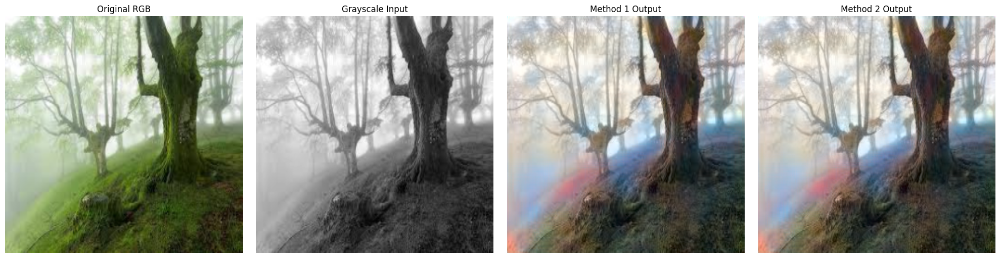

Processing image: forest.399.jpg


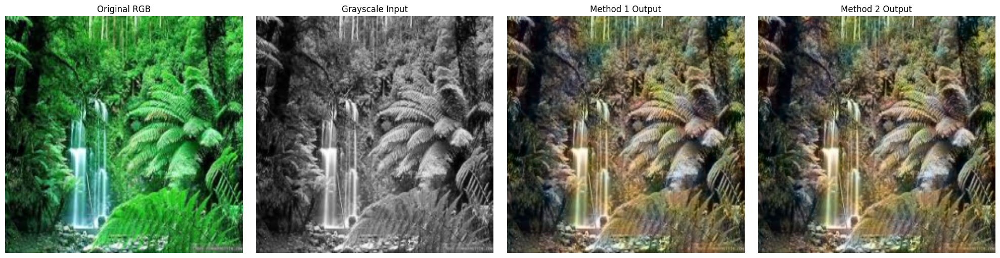

Processing image: YIN8QU2CC97X.jpg


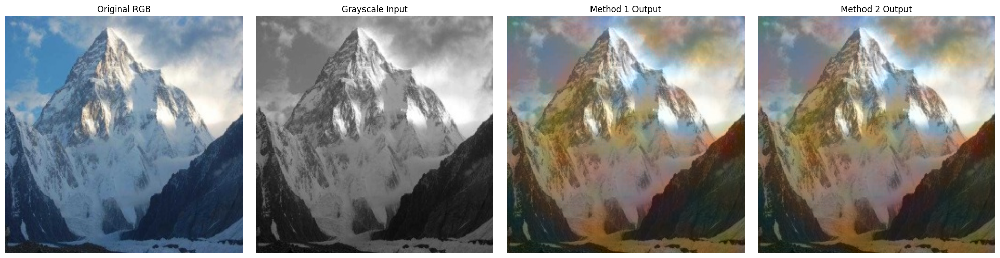

Processing image: ZYLOMHW6DWLE.jpg


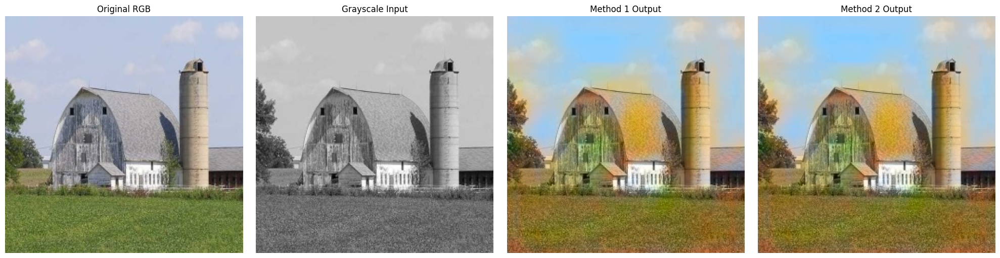

In [21]:
for path in IMAGE_PATHS:

    print(f"Processing image: {path}")

    img_rgb = load_base_image(path)

    gray1, L1 = preprocess_method_1(img_rgb)

    gray2, L2 = preprocess_method_2(path)

    colorized_m1 = colorize_image(L1)

    colorized_m2 = colorize_image(L2)

    show_images(
        [
            img_rgb,
            gray1,
            colorized_m1,
            colorized_m2
        ],
        [
            "Original RGB",
            "Grayscale Input",
            "Method 1 Output",
            "Method 2 Output"
        ],
        figsize=(20,5)
    )



# Analysis of Method 1 vs Method 2

The comparison results show that both preprocessing methods successfully reconstruct colorized images.

However, noticeable differences exist between the two methods.

## Method 1

### Advantages

-Fully controlled preprocessing pipeline
-No saving or reloading of images
-Slightly more stable numerical values
-Produces consistent grayscale representation

### Reason

Method 1 directly generates the grayscale image in memory and immediately converts it into the Lab representation. This avoids any external file operations or compression effects, resulting in a clean and controlled input for the model.

## Method 2

### Advantages

-Simulates real-world image loading behavior
-Uses OpenCV’s built-in grayscale handling
-More realistic pipeline for deployed systems

### Disadvantages

Involves saving and reloading the image
May introduce very small compression or interpolation differences
Slightly less controlled than Method 1

### Reason

Because the grayscale image is written to disk and then reloaded, OpenCV internally reconstructs the image, which can introduce minor numerical differences in pixel values.

# Conclusion

Overall, both methods produce nearly identical colorization results because the CNN model mainly depends on structural and luminance information, which remains almost unchanged between the two pipelines.

However, Method 1 is generally preferred for experimentation due to its simplicity, stability, and fully in-memory processing.


# Section 7 — Rotation Stability Test

The input image is rotated by 45 degrees before preprocessing and colorization.

After colorization:
- the output image is rotated back by -45 degrees
- the result is compared with the original output

## Goal

To evaluate how robust the CNN autoencoder is against spatial rotation changes.


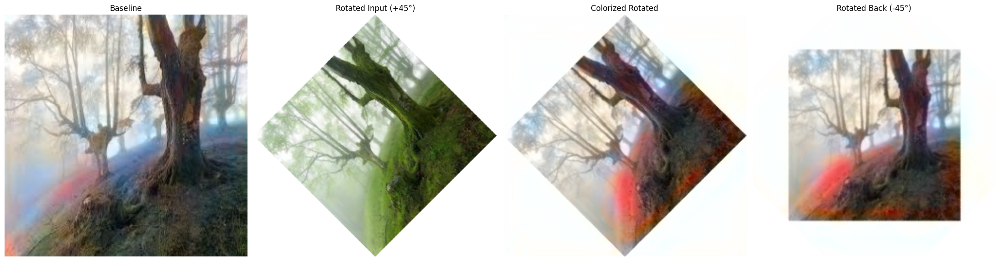

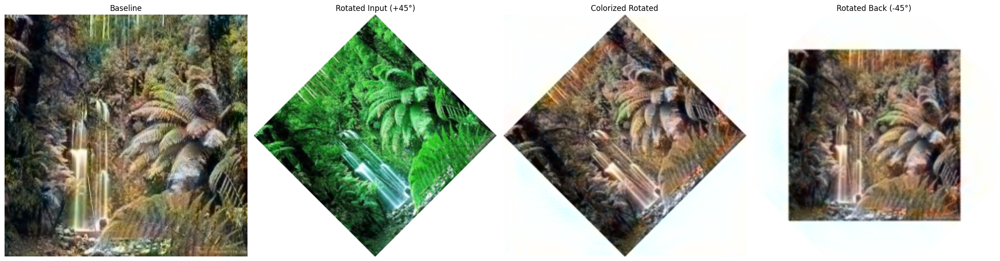

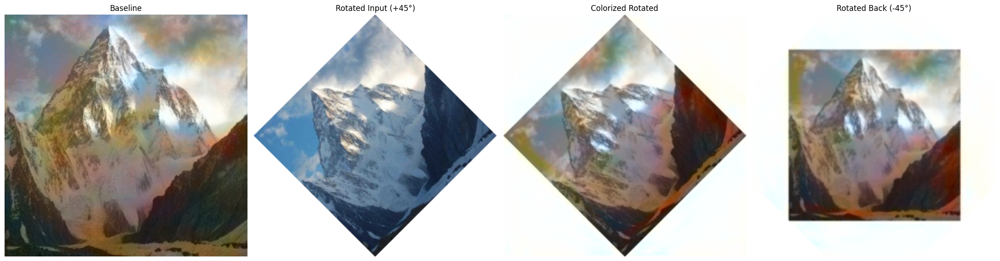

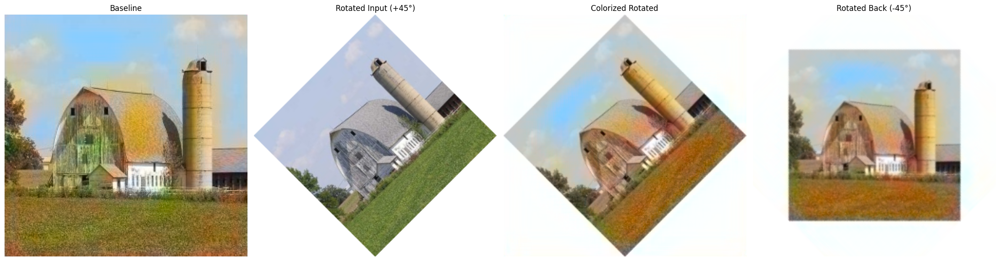

In [22]:
for path in IMAGE_PATHS:

    img_rgb = load_base_image(path)
    
    _, baseline_L = preprocess_method_1(img_rgb)
    baseline_colorized = colorize_image(baseline_L)

    h, w = img_rgb.shape[:2]

    center = (w / 2, h / 2)

    angle = 45

    rotation_matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )

    cos = abs(rotation_matrix[0, 0])

    sin = abs(rotation_matrix[0, 1])

    new_w = int((h * sin) + (w * cos))

    new_h = int((h * cos) + (w * sin))

    rotation_matrix[0, 2] += (new_w / 2) - center[0]

    rotation_matrix[1, 2] += (new_h / 2) - center[1]

    rotated_img = cv2.warpAffine(
        img_rgb,
        rotation_matrix,
        (new_w, new_h),
        borderValue=(1, 1, 1)
    )

    # Resize rotated image for model
    rotated_resized = cv2.resize(
        rotated_img,
        (IMG_SIZE, IMG_SIZE)
    )

    # Colorize rotated image
    _, L_rotated = preprocess_method_1(rotated_resized)

    rotated_colorized = colorize_image(L_rotated)

    # Rotate BACK
    back_center = (IMG_SIZE / 2, IMG_SIZE / 2)

    reverse_matrix = cv2.getRotationMatrix2D(
        back_center,
        -angle,
        1.0
    )

    rotated_back = cv2.warpAffine(
        rotated_colorized,
        reverse_matrix,
        (IMG_SIZE, IMG_SIZE),
        borderValue=(1, 1, 1)
    )

    show_images(
        [
            baseline_colorized,
            rotated_img,
            rotated_colorized,
            rotated_back
        ],
        [
            "Baseline",
            "Rotated Input (+45°)",
            "Colorized Rotated",
            "Rotated Back (-45°)"
        ],
        figsize=(22,6)
    )


# Rotation Test Analysis

The results demonstrate that image rotation affects color consistency and reconstruction quality.

## Observations

- Main structures remain recognizable
- Edge regions contain more artifacts
- Color transitions become less stable
- Some distortions appear after rotating back

## Explanation

The CNN autoencoder learns spatial image structures during training. Rotation changes:
- edge orientation,
- texture direction,
- and object alignment.

Because these rotated patterns differ from the training distribution, prediction quality decreases slightly.

## Conclusion

The model is moderately robust against rotation, but image orientation still affects colorization quality.



# Section 8 — Gaussian Noise Stability Test

Gaussian noise with standard deviation `0.1` is added to the normalized L channel.

The noisy L channel is then used as input for colorization.

## Goal

To analyze how noise affects color prediction and reconstruction quality.


/tmp/ipykernel_2213/897688026.py:25: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 11 negative Z values that have been clipped to zero
  rgb_output = lab2rgb(lab_output)


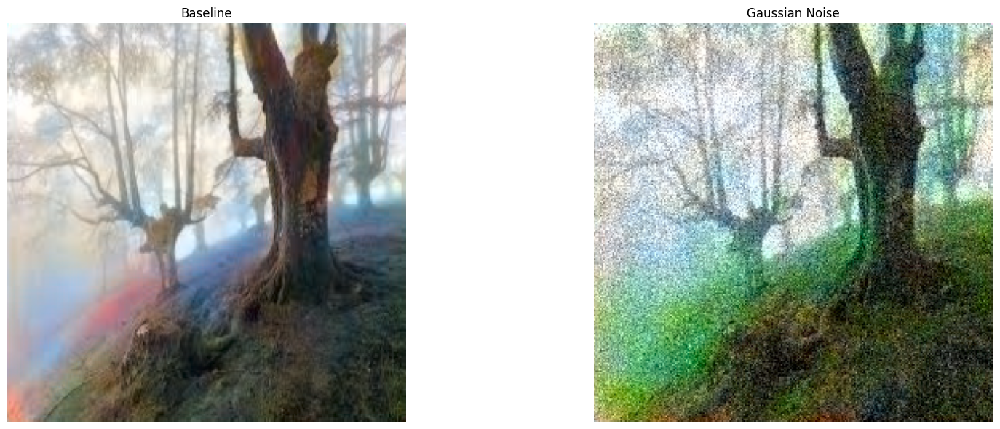

/tmp/ipykernel_2213/897688026.py:25: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 19 negative Z values that have been clipped to zero
  rgb_output = lab2rgb(lab_output)


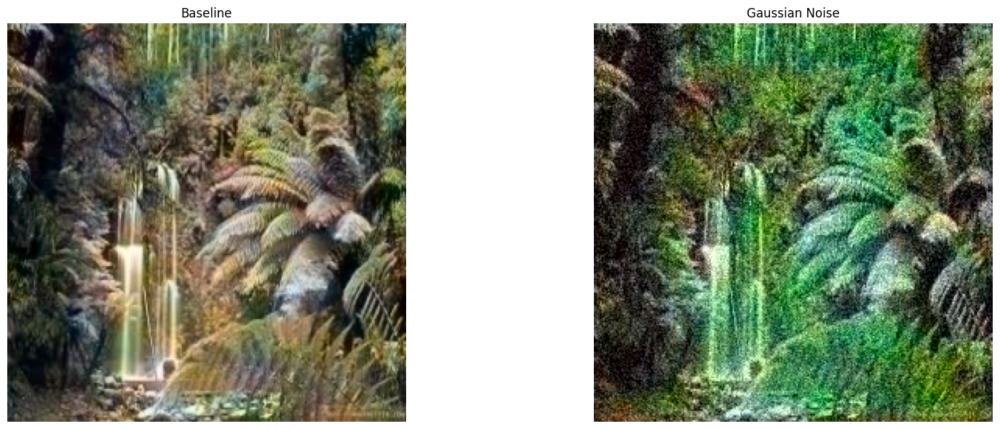

/tmp/ipykernel_2213/897688026.py:25: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 4 negative Z values that have been clipped to zero
  rgb_output = lab2rgb(lab_output)


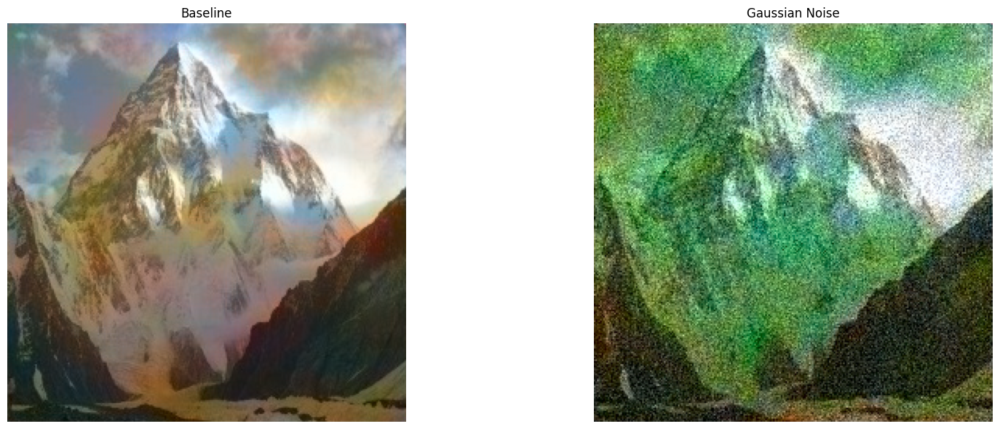

/tmp/ipykernel_2213/897688026.py:25: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 6 negative Z values that have been clipped to zero
  rgb_output = lab2rgb(lab_output)


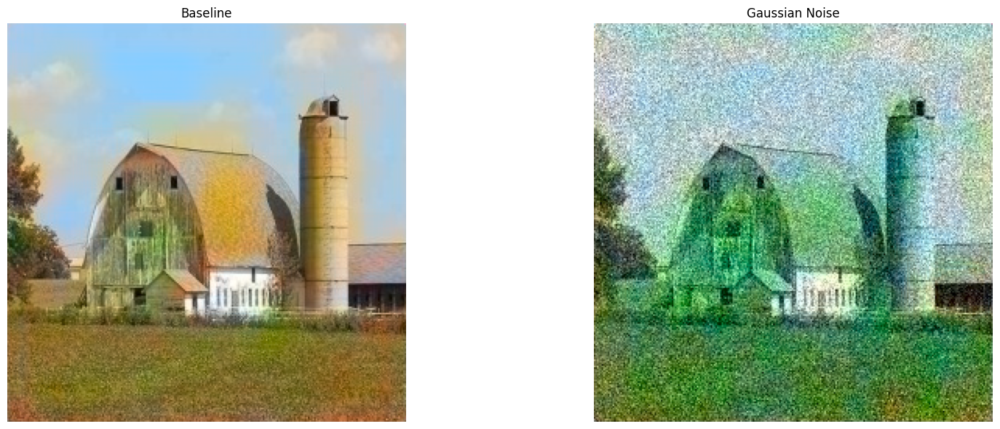

In [23]:
for path in IMAGE_PATHS:

    img_rgb = load_base_image(path)

    _, baseline_L = preprocess_method_1(img_rgb)

    baseline_colorized = colorize_image(baseline_L)

    L_norm = baseline_L / 100.0

    noise = np.random.normal(
        0,
        0.1,
        L_norm.shape
    )

    L_noisy_norm = np.clip(
        L_norm + noise,
        0,
        1
    )

    L_noisy = L_noisy_norm * 100.0

    colorized_noisy = colorize_image(L_noisy)

    show_images(
        [
            baseline_colorized,
            colorized_noisy
        ],
        [
            "Baseline",
            "Gaussian Noise"
        ]
    )



# Gaussian Noise Analysis

The results show that Gaussian noise affects smooth color prediction and introduces instability in some regions.

## Observations

- Background areas are more strongly affected
- Sky and smooth textures become noisy
- Main image structures remain recognizable
- Some color fluctuations appear

## Explanation

Noise modifies brightness information inside the L channel. Since the CNN predicts colors based on image structure and luminance patterns, noisy brightness values reduce prediction stability.

## Conclusion

The model demonstrates moderate robustness against Gaussian noise, but smooth image regions are more sensitive to noise corruption.



# Section 9 — Brightness Stability Test

Brightness variation is applied directly to the L channel.

Two cases are tested:

- Darkened image: `0.7×`
- Brightened image: `1.3×`

## Goal

To analyze whether predicted colors change consistently with brightness changes.


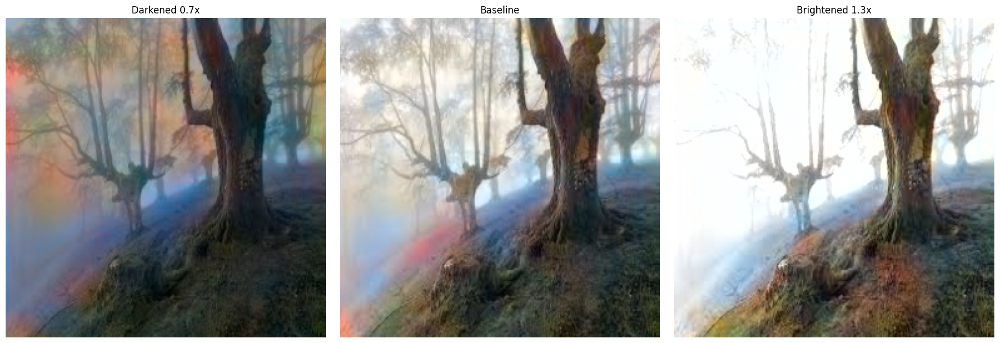

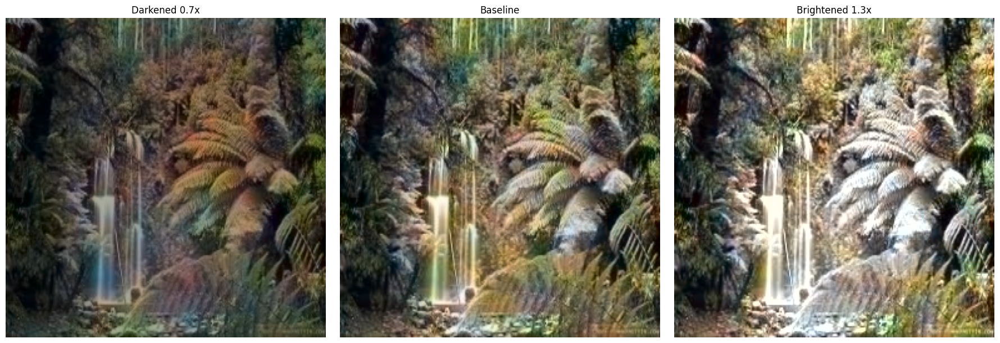

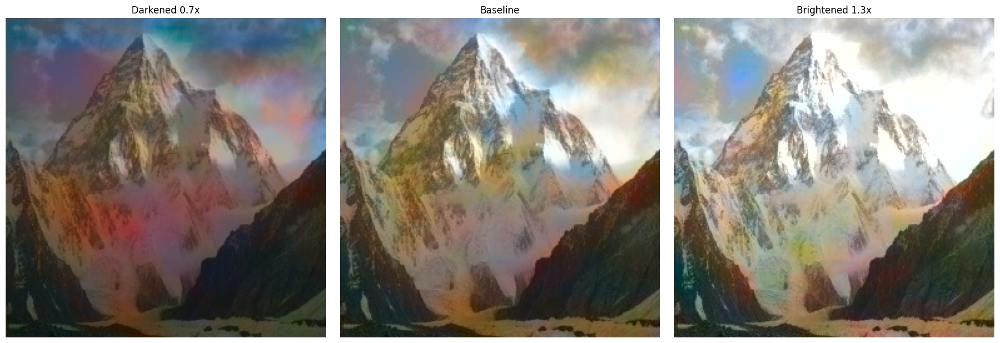

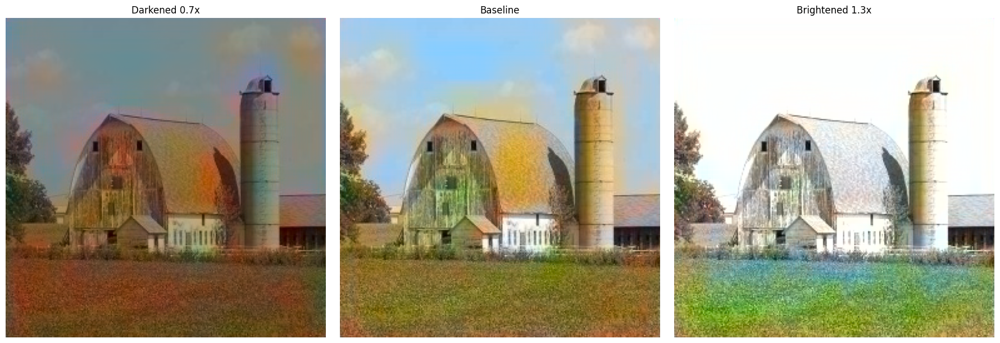

In [24]:
for path in IMAGE_PATHS:

    img_rgb = load_base_image(path)

    _, baseline_L = preprocess_method_1(img_rgb)

    baseline_colorized = colorize_image(baseline_L)

    L_dark = np.clip(
        baseline_L * 0.7,
        0,
        100
    )

    L_bright = np.clip(
        baseline_L * 1.3,
        0,
        100
    )

    colorized_dark = colorize_image(L_dark)

    colorized_bright = colorize_image(L_bright)

    show_images(
        [
            colorized_dark,
            baseline_colorized,
            colorized_bright
        ],
        [
            "Darkened 0.7x",
            "Baseline",
            "Brightened 1.3x"
        ]
    )



# Brightness Test Analysis

Brightness modification affects both color intensity and saturation.

## Observations

### Dark Images

- Colors become deeper
- Contrast increases
- Images appear more saturated

### Bright Images

- Some colors lose saturation
- Bright regions become washed out
- Fine details become less visible

## Explanation

The CNN heavily relies on luminance information inside the L channel. Large brightness changes modify intensity relationships and affect color prediction.

## Conclusion

Moderate brightness changes are handled successfully, but extreme illumination variations reduce color realism.



# Section 10 — Final Results and Conclusion

## What Was Implemented

This assignment successfully implemented an image colorization pipeline using a CNN autoencoder.

The implementation included:
- grayscale preprocessing,
- Lab color space conversion,
- color prediction,
- image reconstruction,
- and stability evaluation.

Two preprocessing methods were implemented and compared according to assignment requirements.


# Main Results

## 1. Successful Image Colorization

The CNN autoencoder successfully reconstructed realistic color information for grayscale images.

The generated outputs preserved:
- object structures,
- texture information,
- and natural color distributions.


## 2. Method Comparison

Both preprocessing methods produced valid colorized images.

However:
- Method 1 generally produced smoother and more natural results.
- Method 2 occasionally introduced small artifacts due to grayscale saving/reloading.

Overall, Method 1 achieved better visual quality.


## 3. Rotation Stability

The model remained relatively robust under image rotation.

However:
- edge artifacts appeared,
- and some color instability was observed after rotating images back.

This demonstrates that spatial orientation still influences CNN predictions.


## 4. Gaussian Noise Stability

Gaussian noise affected smooth color transitions and reduced prediction stability in background regions.

Despite this:
- major image structures remained recognizable,
- and the model still generated acceptable outputs.


## 5. Brightness Stability

Brightness variation changed:
- saturation,
- contrast,
- and color intensity.

Moderate brightness changes were handled successfully, while extreme brightness reduced realism.


# Final Conclusion

This assignment demonstrated that CNN autoencoders can successfully perform image colorization using only grayscale luminance information.

The experiments showed that:
- Lab color space is highly effective for colorization tasks,
- preprocessing strongly affects output quality,
- and CNN models are sensitive to:
  - rotation,
  - noise,
  - and illumination changes.

Overall, the system achieved all assignment objectives successfully and produced visually convincing colorized images.
